Libraries imported successfully!
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


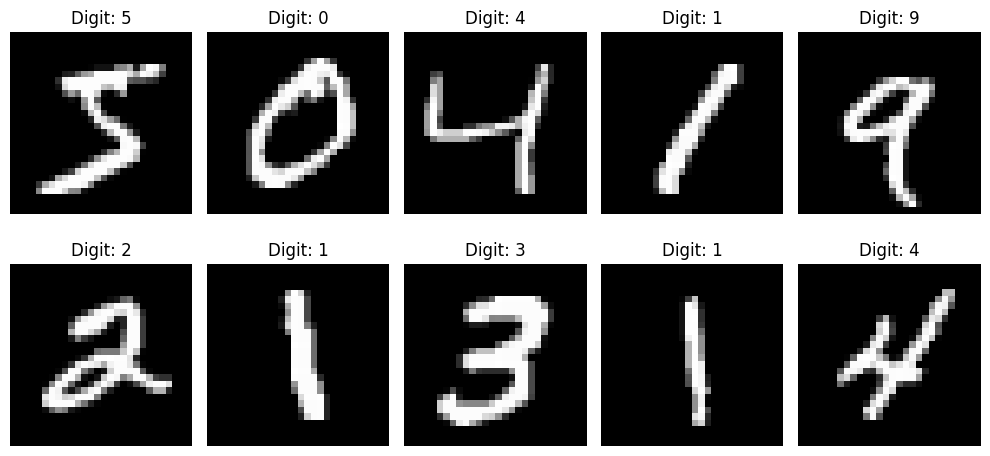

Image preprocessing completed!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

CNN model compiled!
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 99ms/step - accuracy: 0.9052 - loss: 0.3119 - val_accuracy: 0.9817 - val_loss: 0.0647
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 97ms/step - accuracy: 0.9694 - loss: 0.1025 - val_accuracy: 0.9885 - val_loss: 0.0471
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 95ms/step - accuracy: 0.9783 - loss: 0.0736 - val_accuracy: 0.9877 - val_loss: 0.0438
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 93ms/step - accuracy: 0.9816 - loss: 0.0603 - val_accuracy: 0.9887 - val_loss: 0.0406
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 94ms/step - accuracy: 0.9840 - loss: 0.0513 - val_accuracy: 0.9898 - val_loss: 0.0369
Test Loss: 0.030910778790712357
Test Accuracy: 98.9 %


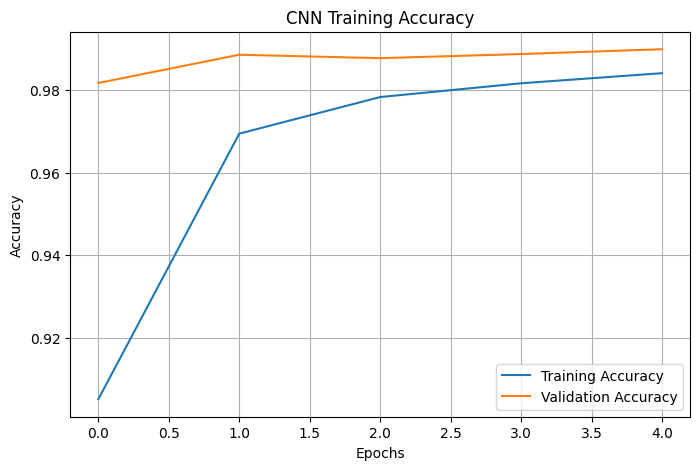

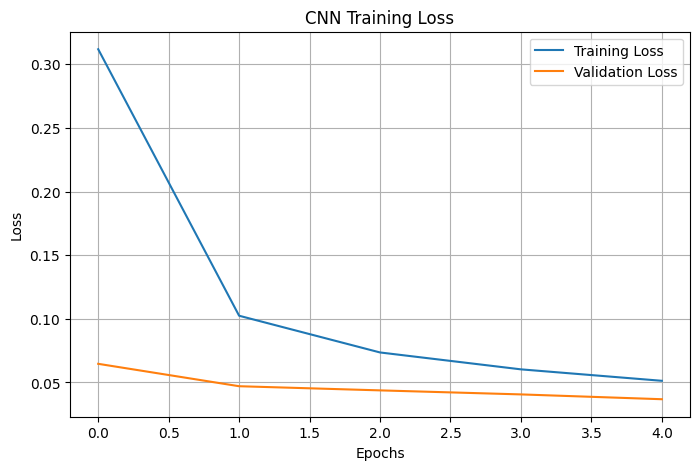

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


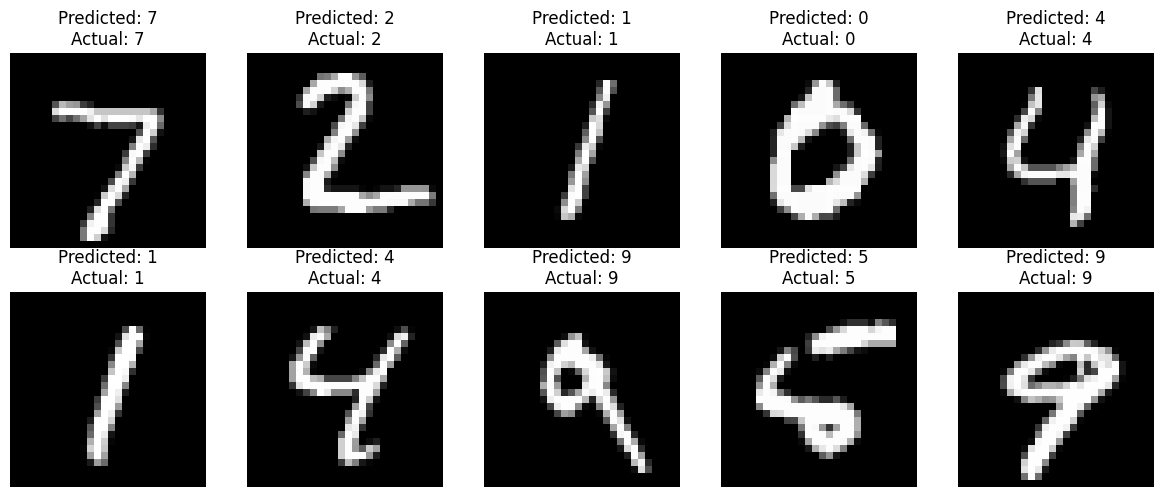


CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.98      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.98      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       1.00      0.97      0.98      1028
           8       0.98      0.99      0.99       974
           9       0.98      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



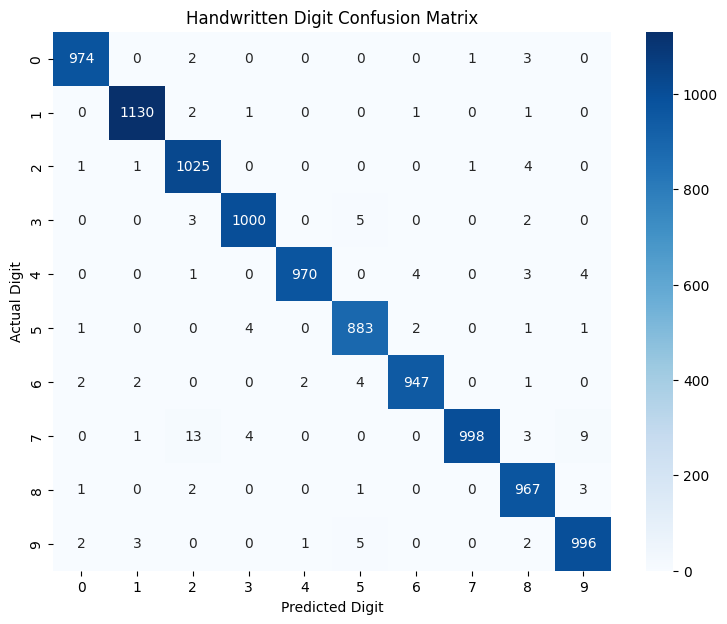

Model saved successfully!
Upload an image of ONE handwritten digit


In [ ]:

# ==========================================
# TASK 3: HANDWRITTEN CHARACTER RECOGNITION
# Dataset: MNIST
# Algorithm: CNN
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)

from sklearn.metrics import classification_report, confusion_matrix

print("Libraries imported successfully!")

# STEP 1: LOAD DATASET

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

# STEP 2: DISPLAY SAMPLE IMAGES

plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i], cmap="gray")

    plt.title("Digit: " + str(y_train[i]))

    plt.axis("off")

plt.tight_layout()
plt.show()

# STEP 3: PREPROCESS IMAGES

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Image preprocessing completed!")

# STEP 4: BUILD CNN MODEL

model = Sequential([

    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),

    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),

    Dropout(0.5),

    Dense(10, activation="softmax")

])

model.summary()

# STEP 5: COMPILE MODEL

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled!")

# STEP 6: TRAIN MODEL

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# STEP 7: EVALUATE MODEL

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)

print("Test Accuracy:",
      round(test_accuracy * 100, 2), "%")

# STEP 8: PLOT ACCURACY

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Training Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()
plt.show()

# STEP 9: PLOT LOSS

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Training Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid()
plt.show()

# STEP 10: PREDICT TEST IMAGES

predictions = model.predict(X_test)

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")

    plt.title(
        "Predicted: " + str(predicted_labels[i]) +
        "\nActual: " + str(y_test[i])
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# STEP 11: CLASSIFICATION REPORT

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    predicted_labels
))

# STEP 12: CONFUSION MATRIX

cm = confusion_matrix(
    y_test,
    predicted_labels
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.title("Handwritten Digit Confusion Matrix")

plt.show()

# STEP 13: SAVE MODEL

model.save("/content/handwritten_digit_model.keras")

print("Model saved successfully!")

# STEP 14: TEST YOUR OWN HANDWRITING

from google.colab import files
from PIL import Image, ImageOps

print("Upload an image of ONE handwritten digit")

uploaded = files.upload()

if uploaded:

    image_path = next(iter(uploaded.keys()))

    img = Image.open(image_path).convert("L")

    if np.mean(np.array(img)) > 127:
        img = ImageOps.invert(img)

    bbox = img.point(
        lambda p: 255 if p > 40 else 0
    ).getbbox()

    if bbox is None:
        raise ValueError("No clear digit detected.")

    img = img.crop(bbox)

    img.thumbnail((20, 20))

    canvas = Image.new("L", (28, 28), 0)

    x = (28 - img.width) // 2
    y = (28 - img.height) // 2

    canvas.paste(img, (x, y))

    image_array = np.array(canvas).astype("float32") / 255.0

    image_array = image_array.reshape(1, 28, 28, 1)

    result = model.predict(image_array)

    digit = np.argmax(result)

    print("\nRECOGNIZED HANDWRITTEN DIGIT:", digit)

    plt.imshow(canvas, cmap="gray")
    plt.title("Predicted Digit: " + str(digit))
    plt.axis("off")
    plt.show()

print("\nTASK 3 COMPLETED SUCCESSFULLY!")
